In [0]:
from pyspark.sql import functions as F
import matplotlib.pyplot as plt

df_movies = spark.table("workspace.retail_analytics.gold_movies")
df_genres = spark.table("workspace.retail_analytics.gold_genres")

print("Películas:", df_movies.count())
print("Géneros:", df_genres.count())

Películas: 9718
Géneros: 19


In [0]:
resumen = df_movies.agg(
    F.count("*").alias("total_peliculas"),
    F.round(F.avg("user_score"), 2).alias("puntuacion_promedio"),
    F.countDistinct("release_year").alias("anios_con_lanzamientos"),
    F.sum(
        F.when(F.col("budget_usd").isNotNull(), 1).otherwise(0)
    ).alias("peliculas_con_presupuesto")
)

display(resumen)

total_peliculas,puntuacion_promedio,anios_con_lanzamientos,peliculas_con_presupuesto
9718,6.63,110,6735


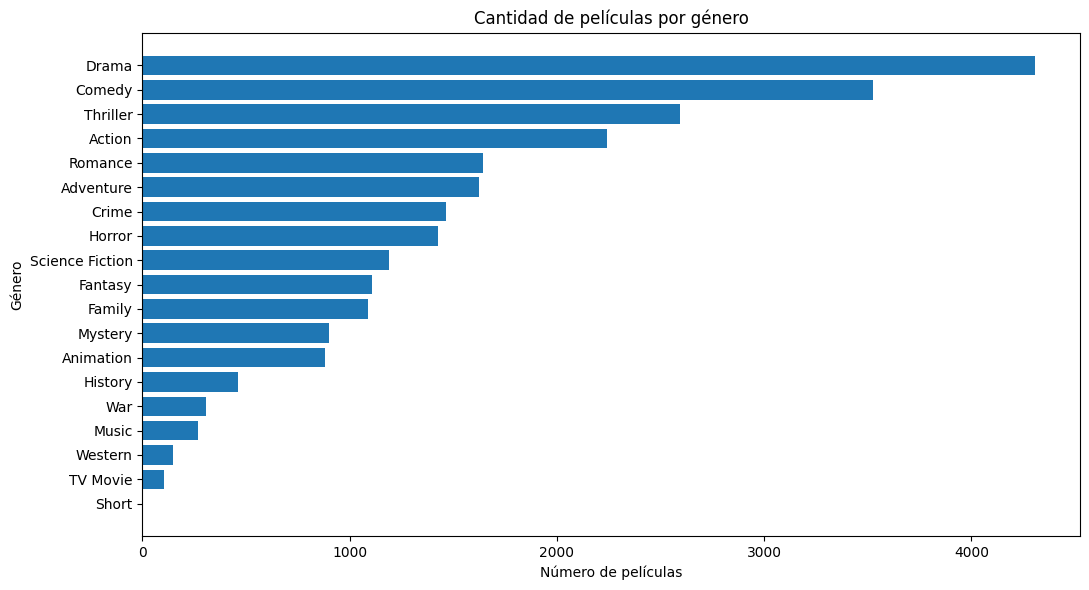

In [0]:

generos = (
    df_genres
    .select("genre", "movies_count")
    .orderBy(F.desc("movies_count"))
    .toPandas()
)

plt.figure(figsize=(11, 6))
plt.barh(
    generos["genre"][::-1],
    generos["movies_count"][::-1]
)
plt.title("Cantidad de películas por género")
plt.xlabel("Número de películas")
plt.ylabel("Género")
plt.tight_layout()
plt.show()


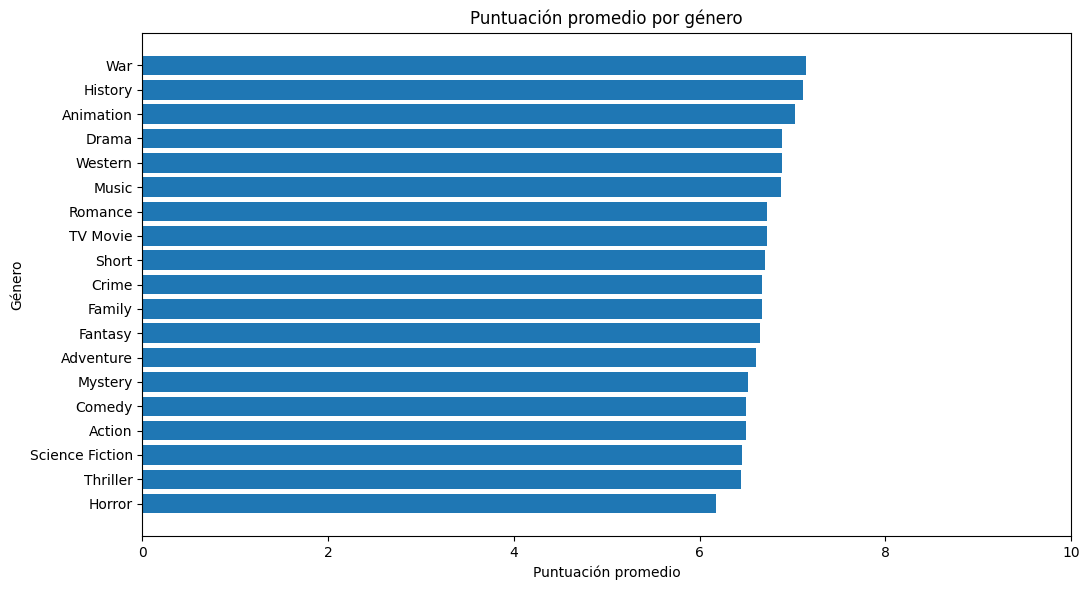

In [0]:

puntuaciones = (
    df_genres
    .select("genre", "avg_user_score")
    .dropna(subset=["avg_user_score"])
    .orderBy(F.desc("avg_user_score"))
    .toPandas()
)

plt.figure(figsize=(11, 6))
plt.barh(
    puntuaciones["genre"][::-1],
    puntuaciones["avg_user_score"][::-1]
)
plt.title("Puntuación promedio por género")
plt.xlabel("Puntuación promedio")
plt.ylabel("Género")
plt.xlim(0, 10)
plt.tight_layout()
plt.show()


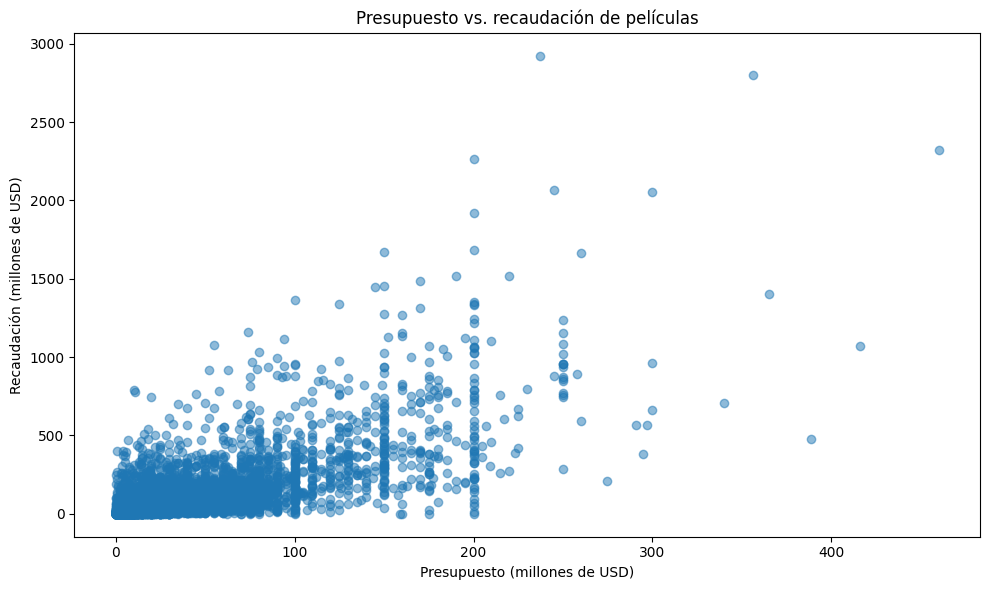

Películas incluidas en el gráfico: 6127


In [0]:

finanzas = (
    df_movies
    .filter(
        F.col("budget_usd").isNotNull() &
        F.col("revenue_usd").isNotNull() &
        (F.col("budget_usd") > 0) &
        (F.col("revenue_usd") > 0)
    )
    .select("budget_usd", "revenue_usd", "title")
    .toPandas()
)

plt.figure(figsize=(10, 6))
plt.scatter(
    finanzas["budget_usd"] / 1_000_000,
    finanzas["revenue_usd"] / 1_000_000,
    alpha=0.5
)
plt.title("Presupuesto vs. recaudación de películas")
plt.xlabel("Presupuesto (millones de USD)")
plt.ylabel("Recaudación (millones de USD)")
plt.tight_layout()
plt.show()

print("Películas incluidas en el gráfico:", len(finanzas))
